# Практическая работа № 10 — уровень B

Выбор числа кластеров по методу локтя и коэффициенту силуэта с содержательной интерпретацией сегментов.

,inertia,silhouette
k,,
2,1140.978,0.529
3,387.044,0.667
4,265.410,0.652
5,230.779,0.499
6,199.826,0.402
7,180.933,0.402
8,164.546,0.322
9,149.365,0.318
10,140.517,0.319


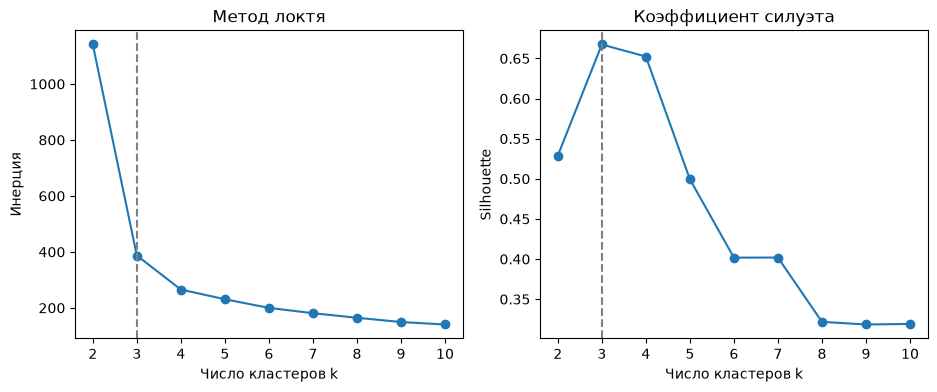

Профили кластеров при k = 3:


,avg_check,purchases_month,days_since_last,discount_share,clients
cluster,,,,,
0,5175.85,2.78,20.62,0.14,210
1,884.42,6.94,6.14,0.59,220
2,1543.98,0.70,91.95,0.33,170


ARI для random_state=42 и 123: 1.000


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

FEATURES = ['avg_check', 'purchases_month', 'days_since_last', 'discount_share']
df = pd.read_csv('../raw/customers.csv')
X = StandardScaler().fit_transform(df[FEATURES])

rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(X)
    rows.append({'k': k, 'inertia': model.inertia_, 'silhouette': silhouette_score(X, labels)})
criteria = pd.DataFrame(rows).set_index('k')
display(criteria.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(criteria.index, criteria['inertia'], marker='o')
axes[0].set(title='Метод локтя', xlabel='Число кластеров k', ylabel='Инерция')
axes[1].plot(criteria.index, criteria['silhouette'], marker='o')
axes[1].set(title='Коэффициент силуэта', xlabel='Число кластеров k', ylabel='Silhouette')
for ax in axes:
    ax.set_xticks(criteria.index); ax.axvline(3, color='gray', linestyle='--')
plt.show()

SELECTED_K = 3
labels_42 = KMeans(n_clusters=SELECTED_K, n_init=20, random_state=42).fit_predict(X)
df['cluster'] = labels_42
profile = df.groupby('cluster')[FEATURES].mean().round(2)
profile['clients'] = df.groupby('cluster').size()
print('Профили кластеров при k = 3:')
display(profile)
labels_123 = KMeans(n_clusters=SELECTED_K, n_init=20, random_state=123).fit_predict(X)
print(f'ARI для random_state=42 и 123: {adjusted_rand_score(labels_42, labels_123):.3f}')

## Вывод

Силуэт максимален при `k=3` (0.667), а после перехода от 2 к 3 кластерам инерция уменьшается наиболее заметно. Поэтому выбран `k=3`: высокочековые клиенты, частые покупатели со скидками и неактивные клиенты. ARI=1.0 при смене `random_state`, то есть разбиение устойчиво.